# Detector de voz sintética: v6 (funil: front-end, fusão, cabeça, maximização)

> **O que é:** um detector que diz se uma voz foi gerada por IA. Treinado em inglês, testado também em português.
> **O que a v6 pergunta:** com o mesmo pipeline da v4 e da v5 (um modelo de fala pré-treinado e **congelado**, com uma cabeça leve por cima), (1) qual "ouvido" usar: o da **Meta** (XLS-R), o da **Microsoft** (WavLM) ou **os dois juntos**; (2) qual cabeça: **regressão logística, MLP ou CNN**; (3) quanto se ganha **apertando** a cabeça vencedora.
> **Como decidimos:** em seis etapas, como um funil; cada etapa só usa **validação + dev_shift**; os bancos de teste só aparecem na etapa 6, uma vez, para os finalistas declarados antes.

Este notebook **só lê** resultados já calculados (`scripts/vigia_v6.ps1` → `scripts/rodar_v6.ps1` → `scripts/v6.py` e `scripts/v6_teste.py`). Ele não treina nem consulta o teste (`AVALIAR_TESTE_FINAL = False`): os números da seção 7 vêm do arquivo gravado pela etapa 6.

## Histórico das versões (resumo)

| versão | o que mudou | resultado em uma frase |
|:--|:--|:--|
| v1 a v3 | CNN pequena sobre log-mel (augmentation, padding) | ótima na validação e **invertida** nas vozes de internet (AUC do dev_shift 0,15 a 0,39) |
| v4 | XLS-R 300M (Meta) congelado + regressão logística | resolveu a inversão (dev_shift AUC 0,983; In-the-Wild 0,979); fraco em pt-BR |
| v5 | WavLM Large (Microsoft) no lugar do XLS-R | empate no dev_shift, pior no teste, sobretudo em pt-BR; o projeto seguiu com o XLS-R |
| **v6** | **funil: os dois modelos, a fusão, três cabeças e o ajuste fino**, com a métrica nova "AUC da pior fonte" | ver a tabela do funil (seção 6) e as conclusões (seção 8) |

Registro completo: `docs/HISTORICO_VERSOES.md`; decisões da v6: `docs/DECISOES_V6.md`.

## 1. Introdução

### 1.1 O ponto de partida
Na v4, um modelo de fala pré-treinado (o **XLS-R**, da Meta) foi usado **congelado**, só como "extrator de características": cada áudio vira, em cada uma das 25 saídas do modelo, um vetor de 1.024 números (a média no tempo). Em cima disso, uma **regressão logística** decide real × fake. Isso é **transfer learning** (Aula 10): aproveitar o que um modelo aprendeu com muitos dados (aqui, ~436 mil horas de fala em 128 línguas) num problema novo com poucos dados rotulados. ⚠️ Fora da trilha: o modelo auto-supervisionado em si (a trilha faz transfer learning com um modelo de imagem).

Na v5, o colega trocou o XLS-R pelo **WavLM** (Microsoft, só inglês, pré-treinado também a "limpar" fala com ruído). Deu empate na decisão e pior no teste. Mas os dois modelos erraram em lugares diferentes, o que levanta a pergunta: **e se usarmos os dois?**

### 1.2 O funil (seis etapas, nesta ordem)
1. **E1 · Meta × Microsoft:** o mesmo pipeline nos dois modelos, nesta máquina, com notas por clipe (para poder comparar e juntar).
2. **E2 · Fusão:** três jeitos de juntar os dois (média das notas, stacking, vetores colados).
3. **E3 · Front-end:** só Meta, só Microsoft ou a fusão.
4. **E4 · Cabeça:** regressão logística, MLP ou CNN sobre o vencedor.
5. **E5 · Maximização:** uma modificação de cada vez na cabeça vencedora, e a regra do limiar.
6. **E6 · Teste:** os finalistas F0 (v4), F1 (front-end vencedor + cabeça básica) e F2 (sistema final), **uma vez**.

### 1.3 A métrica nova: AUC da **pior** fonte
Até a v5, escolhíamos pela **EER média por fonte**. A média esconde uma fonte ruim atrás de fontes fáceis (no DFADD a EER é quase 0%). Na v6, a métrica primária é a **AUC da pior fonte** entre as quatro "fontes de decisão": DFADD, ShiftySpeech e CodecFake+ (da validação) e o **dev_shift** (vozes de internet, 16 locutores do In-the-Wild). A AUC (área sob a curva ROC) mede se o modelo **ordena** bem real e fake, sem depender de limiar nem da proporção de cada classe: 0,5 é chute, 1,0 é perfeito.

### 1.4 As regras (pré-registradas antes de qualquer resultado)
- **Diferença relevante:** no bootstrap pareado (2.000 reamostragens, sorteando **locutores**), o intervalo de 95% da diferença de AUC da pior fonte **não inclui o zero**, e a diferença é de pelo menos **0,005**. ⚠️ Fora da trilha: o bootstrap.
- **Empate → vence o mais simples** (só Meta < só Microsoft < fusão; RL < MLP < CNN). É a ideia de **regularização** da aula de overfitting aplicada à escolha do modelo: na dúvida, menos parâmetros.
- **O teste não escolhe nada.** Os seis bancos de teste já tinham sido vistos na v4 e na v5; a E6 só mostra os finalistas.

## 2. Configuração

**O que faz:** define **todos os hiperparâmetros numa célula só** (tag `config`). Os scripts (`scripts/v6.py`, `scripts/v6_teste.py`) executam exatamente esta célula, então não há números copiados em dois lugares. `QUICK = True` roda tudo com poucos clipes (teste de ponta a ponta); `AVALIAR_TESTE_FINAL = False` garante que nada aqui consulta o teste.

In [1]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (poucos clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V6_QUICK") == "1")   # --quick / V6_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: este notebook e o scripts/v6.py NÃO consultam o teste (a E6 é um script separado)
VERSAO = "v6"
SEED = 42                    # seed dos DADOS (plano de clipes, herdado do v4_cache) e do bootstrap
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V6_NUM_WORKERS (não muda o método)

# ---------------- os dois front-ends congelados (E1) ----------------
MODELOS = {"xlsr": "facebook/wav2vec2-xls-r-300m",      # Meta: 128 línguas, ~436 mil h (o da v4)
           "wavlm": "microsoft/wavlm-large"}           # Microsoft: inglês, ~94 mil h (o da v5)
NOME_MODELO = {"xlsr": "Meta (XLS-R 300M)", "wavlm": "Microsoft (WavLM Large)"}
REVISAO_WAVLM = "c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c"   # a mesma revisão do colega (v5)
DTYPE = "float16"            # como na v4/v5 (lote com NaN é refeito em bfloat16)
TOP_DB, MIN_S, MAX_S = 35.0, 0.5, 8.0   # corte de silêncio de 35 dB; recorte central de até 8 s (como na v4)

# ---------------- extração do WavLM (mesmos clipes do v4_cache) ----------------
ORCAMENTO_EXTRACAO_H = 3.0   # treino + validação + dev_shift do WavLM (cumulativo entre tentativas)
ORCAMENTO_TESTE_H = 2.0      # teste do WavLM (só na E6, só se o vencedor usar o WavLM)
TAM_SHARD = 2000             # o mesmo da v4 (só para o teste; treino/val/dev copiam o plano da v4)
MAX_AMOSTRAS_LOTE, MAX_CLIPES_LOTE, BALDE_S = 32 * 128_000, 64, 2   # lotes da GPU da v4/v5
VAZAO_ESTIMADA = 25.0        # clipes/s, só até a extração medir a sua
N_MEDIR = 500                # clipes da medição de vazão

# ---------------- métricas e regra de decisão (pré-registro) ----------------
FONTES_VAL = ("dfadd", "shiftyspeech", "codecfake_plus")   # fontes da validação com as duas classes; + dev_shift
N_BOOT, SEED_BOOT = 2000, 42 # bootstrap pareado por locutor (por clipe no CodecFake+)
DIF_MIN = 0.005              # diferença mínima de AUC da pior fonte para "relevante" (com o IC95 sem o zero)

# ---------------- E1 (RL por camada; a mesma grade da v4) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]
RL_MAX_ITER = 1000
TOP_K = (3, 4)               # concat_top3 e concat_top4
V4_REF = {"modelo": "xlsr", "camadas": [5, 6, 7], "C": 0.1}   # F0: a cabeça final da v4

# ---------------- E2 (fusão) ----------------
STACK_C = 1.0                # C da RL de 2 entradas do stacking (como o S3 da v4)

# ---------------- E4 (cabeças básicas) ----------------
C_BASICO = 1.0               # RL básica: o padrão do scikit-learn, sem ajuste
NN = dict(OCULTA=256, DROPOUT=0.3, LR=1e-3, WD=1e-3, MAX_EPOCAS=30, PACIENCIA=5, BATCH=256)
CNN_CANAIS, CNN_K = 64, 3
SEEDS = (42, 123, 2026)

# ---------------- E5 (maximização) ----------------
E5_GANHO_MIN = 0.003         # a modificação fica se a AUC da pior fonte subir pelo menos isso...
E5_QUEDA_DEV_MAX = 0.01      # ... e a AUC do dev_shift não cair mais que isso
GRADE_C_AMPLA = [float(c) for c in np.logspace(-4, 1, 8)]   # 1e-4 a 10, 8 valores
E5_FPR_D = 0.05              # regra D: 5% de falso alarme nos reais de cada fonte
E5_LIMIAR_DIF_MIN = 0.005    # regra de limiar: C ou D só trocam a A se ganharem isso em acurácia balanceada
E5_NN = dict(WD=1e-2, DROPOUT=0.5, MAX_EPOCAS=60, PACIENCIA=10)   # se a vencedora for MLP/CNN

# ---------------- E6 (teste, script separado) ----------------
TESTE_MAX_POR_CLASSE, TESTE_N_BOOT, TESTE_SEED_BOOT = 5_000, 1_000, 42   # os mesmos da v4/v5
PROJ_N = 6000                # pontos do t-SNE (projeção 2D)

if QUICK:
    N_BOOT, N_MEDIR = 200, 40
    GRADE_C = [1e-2, 1.0]
    GRADE_C_AMPLA = [1e-3, 1e-1, 10.0]
    NN = dict(NN, MAX_EPOCAS=3, PACIENCIA=2, BATCH=32)
    E5_NN = dict(E5_NN, MAX_EPOCAS=4, PACIENCIA=2)
    ORCAMENTO_EXTRACAO_H, ORCAMENTO_TESTE_H = 0.5, 0.5
    TESTE_MAX_POR_CLASSE, TESTE_N_BOOT, PROJ_N = 20, 100, 200

HP = dict(SEED=SEED, NUM_WORKERS=NUM_WORKERS, DTYPE=DTYPE, TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S,
          TAM_SHARD=TAM_SHARD, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE, MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S,
          VAZAO_ESTIMADA=VAZAO_ESTIMADA, N_BOOT=N_BOOT, SEED_BOOT=SEED_BOOT, DIF_MIN=DIF_MIN, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K=TOP_K, V4_REF=V4_REF, STACK_C=STACK_C, C_BASICO=C_BASICO, NN=NN,
          CNN_CANAIS=CNN_CANAIS, CNN_K=CNN_K, SEEDS=SEEDS, E5_GANHO_MIN=E5_GANHO_MIN,
          E5_QUEDA_DEV_MAX=E5_QUEDA_DEV_MAX, GRADE_C_AMPLA=GRADE_C_AMPLA, E5_FPR_D=E5_FPR_D,
          E5_LIMIAR_DIF_MIN=E5_LIMIAR_DIF_MIN, E5_NN=E5_NN, TESTE_MAX_POR_CLASSE=TESTE_MAX_POR_CLASSE,
          TESTE_N_BOOT=TESTE_N_BOOT, TESTE_SEED_BOOT=TESTE_SEED_BOOT, PROJ_N=PROJ_N, FONTES_VAL=FONTES_VAL)
# o que define o MÉTODO da extração do WavLM (igual ao da v5; se mudar, o cache não serve: o script para)
CFG_EXTRACAO = dict(modelo=MODELOS["wavlm"], dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=16_000,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V6_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
_SUF_V4 = "_quick_t2" if QUICK else ""                        # caches QUICK da v4 (já existem em disco)
CACHE = {"xlsr": Path("data/processed") / f"v4_cache{_SUF_V4}",              # XLS-R: o cache da v4 (não reextraído)
         "wavlm": Path("data/processed") / f"v6_wavlm_cache{SUFIXO}"}       # WavLM: extraído na v6, mesmo plano
CACHE_TESTE = {"xlsr": Path("data/processed") / f"v4_cache_teste{_SUF_V4}",
               "wavlm": Path("data/processed") / f"v6_wavlm_cache_teste{SUFIXO}"}
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
PARCIAL = RESULTS_DIR / f"v6_parcial{SUFIXO}"                 # pedaços retomáveis (fora do git)
ETAPAS = ("medir", "extracao", "e1", "e2", "e3", "e4", "e5", "finalistas")


def arq(nome, ext):
    return RESULTS_DIR / f"v6_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"v6_{etapa}_concluido{SUFIXO}.json"


print(f"{VERSAO} | QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | bootstrap {N_BOOT} | "
      f"caches: {CACHE['xlsr']} e {CACHE['wavlm']}")

v6 | QUICK = False | AVALIAR_TESTE_FINAL = False | bootstrap 2000 | caches: data\processed\v4_cache e data\processed\v6_wavlm_cache


**Cada hiperparâmetro em uma frase:**

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `MODELOS` | XLS-R 300M (Meta) e WavLM Large (Microsoft) | os dois modelos já testados (v4 e v5); nenhum terceiro, porque a regra da rodada só permitia baixar o WavLM |
| `REVISAO_WAVLM` | `c1423ed…` | a mesma versão dos pesos que o colega usou na v5 |
| `DTYPE` | float16 | metade da memória e ~2× mais rápido; a v5 mediu erro de 0,04 a 0,06% contra o float32 |
| `TOP_DB`, `MIN_S`, `MAX_S` | 35 dB, 0,5 s, 8 s | o pré-processamento da v4 (corte de silêncio nas bordas; até 8 s do meio do áudio) |
| `ORCAMENTO_EXTRACAO_H` | 3 h | teto de tempo da extração do WavLM (medido: ~35 clipes/s, ~35 min) |
| `FONTES_VAL` + dev_shift | DFADD, ShiftySpeech, CodecFake+, dev_shift | as fontes com real e fake onde dá para medir AUC sem tocar no teste |
| `N_BOOT`, `SEED_BOOT` | 2.000, 42 | intervalos estáveis; os mesmos sorteios para todos os sistemas (comparação pareada) |
| `DIF_MIN` | 0,005 | diferença de AUC abaixo disso não muda nada na prática |
| `GRADE_C` | 0,001 a 1 | a grade da v4 (assim dá para conferir a reprodução); C é o inverso da força da regularização L2 |
| `TOP_K` | 3 e 4 | as concatenações de camadas que a v4 e a v5 já usaram |
| `V4_REF` | XLS-R, camadas 5, 6, 7, C = 0,1 | a cabeça final da v4 (F0, a referência) |
| `STACK_C` | 1 | o C do stacking da v4 (S3); com 2 entradas quase não há o que regularizar |
| `C_BASICO` | 1 | "básica" = sem ajuste; o padrão do scikit-learn |
| `NN` | 256 neurônios, dropout 0,3, AdamW lr 0,001, wd 0,001, lote 256, até 30 épocas, paciência 5 | a MLP da v4; nada novo para ajustar; o early stopping evita overfitting |
| `CNN_CANAIS`, `CNN_K` | 64, 3 | uma CNN pequena (2 convoluções) para não ter muito mais parâmetros que o MLP |
| `SEEDS` | 42, 123, 2026 | a v3 mostrou que a seed sozinha muda muito uma rede; a RL não precisa (é determinística) |
| `E5_GANHO_MIN`, `E5_QUEDA_DEV_MAX` | +0,003 e −0,01 | ajuste fino só fica se ajudar a pior fonte sem piorar as vozes de internet |
| `GRADE_C_AMPLA` | 8 valores de 0,0001 a 10 | a modificação (2) da E5: procurar a regularização certa numa faixa maior |
| `E5_FPR_D` | 5% | a regra de limiar D aceita 5% de falso alarme em cada fonte |
| `TESTE_*` | 5.000 por classe e banco, 1.000 bootstraps | os mesmos 51.320 clipes e a mesma regra da v4 e da v5 |

**O que faz:** funções pequenas para ler tabelas, figuras e arquivos JSON do disco (nada é recalculado).

In [2]:
from pathlib import Path
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def existe(p):
    return Path(p).exists()


def ler(p, padrao=None):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else padrao


def pendente(o_que):
    display(Markdown(f"> **Pendente:** {o_que} ainda não existe em disco (a etapa não terminou ou os arquivos "
                     "ficam fora do git). Rode `scripts\\vigia_v6.ps1` e execute o notebook de novo."))


def figura(p, largura=None):
    if existe(p):
        display(Image(filename=str(p), width=largura))
    else:
        pendente(f"a figura `{p}`")


def tabela(p, colunas=None, arred=4, filtro=None):
    if not existe(p):
        pendente(f"a tabela `{p}`")
        return None
    t = pd.read_csv(p)
    if filtro is not None:
        t = filtro(t)
    if colunas:
        t = t[[c for c in colunas if c in t.columns]]
    display(t.round(arred))
    return t


def f4(x):
    try:
        return f"{float(x):.4f}"
    except (TypeError, ValueError):
        return "—"


def pct(x):
    try:
        return f"{100 * float(x):.1f}%"
    except (TypeError, ValueError):
        return "—"


R = RESULTS_DIR
print("arquivos lidos de", R.resolve(), "| sufixo:", repr(SUFIXO))

arquivos lidos de C:\Projetos\projeto_final_AI\results | sufixo: ''


## 3. Mapa do banco (resumo)

O banco **não mudou** desde a v2 (mesmo manifest, SHA-256 `f2309eb3…`). O mapa completo está em `docs/dataset_overview.md` e no notebook da v1. **O que é novo na v6:** o WavLM foi extraído **nos mesmos clipes** do cache da v4 (o plano foi copiado), e o código confere, clipe a clipe, que os dois modelos têm o mesmo `idx_manifest` e o mesmo caminho, na mesma ordem.

In [3]:
e1 = ler(R / f"v6_e1_resumo{SUFIXO}.json")
if e1:
    display(Markdown("**Clipes conferidos nos dois modelos** (mesmos índices e caminhos, na mesma ordem):"))
    display(pd.DataFrame(e1["identidade_clipes"]).T)
    display(Markdown("**Fontes de decisão e unidade do bootstrap** (locutor quando há `speaker_id`; senão, clipe):"))
    display(pd.DataFrame(e1["bootstrap"]).T)
    nv = R / f"v6_notas_e1_val{SUFIXO}.parquet"
    if existe(nv):
        v = pd.read_parquet(nv)
        d = pd.read_parquet(R / f"v6_notas_e1_dev_shift{SUFIXO}.parquet")
        t = pd.concat([v.assign(conjunto="validação"), d.assign(conjunto="dev_shift")])
        display(t.groupby(["conjunto", "source_dataset", "label"]).size().unstack("label").rename(columns={0: "real", 1: "fake"}))
else:
    pendente("o resumo da E1")

**Clipes conferidos nos dois modelos** (mesmos índices e caminhos, na mesma ordem):

,clipes,mesmos_idx_e_caminhos,excluidos_erro_leitura
treino,40000,True,0
val,19999,True,0
dev_shift,10614,True,0


**Fontes de decisão e unidade do bootstrap** (locutor quando há `speaker_id`; senão, clipe):

,unidade,n_grupos,n_clipes
dfadd,locutor,22,13167
shiftyspeech,locutor,12,4628
codecfake_plus,clipe,352,352
dev_shift,locutor,16,10614


label                       real     fake
conjunto  source_dataset                 
dev_shift in_the_wild     8633.0   1981.0
validação codecfake_plus   164.0    188.0
          dfadd           2831.0  10336.0
          librispeech     1852.0      NaN
          shiftyspeech    1157.0   3471.0

**Conclusão:** treino de 40.000 clipes (metade real, metade fake), validação de 19.999 e dev_shift inteiro (10.614), os mesmos para os dois modelos e para todas as etapas. O CodecFake+ da validação é pequeno (352 clipes, sem locutor), por isso o bootstrap nele sorteia clipes.

## 4. Visualização: como os vetores se organizam

**O que faz:** projeta em 2D os vetores de 1.024 números da **melhor camada única** (E4) e, para contraste, da **última camada** (24), numa amostra de até 6.000 clipes da validação e do dev_shift (o mesmo número por fonte, quando dá). À esquerda de cada par, a cor é real × fake; à direita, a fonte. **Por quê:** ver se real e fake ficam separados e se o modelo agrupa os áudios mais por **banco de origem** (gravação) do que por real/fake, um sinal de atalho. ⚠️ Fora da trilha: PCA (a projeção linear que guarda mais variância) e t-SNE (uma projeção não linear que preserva vizinhos; as distâncias grandes no t-SNE não querem dizer nada).

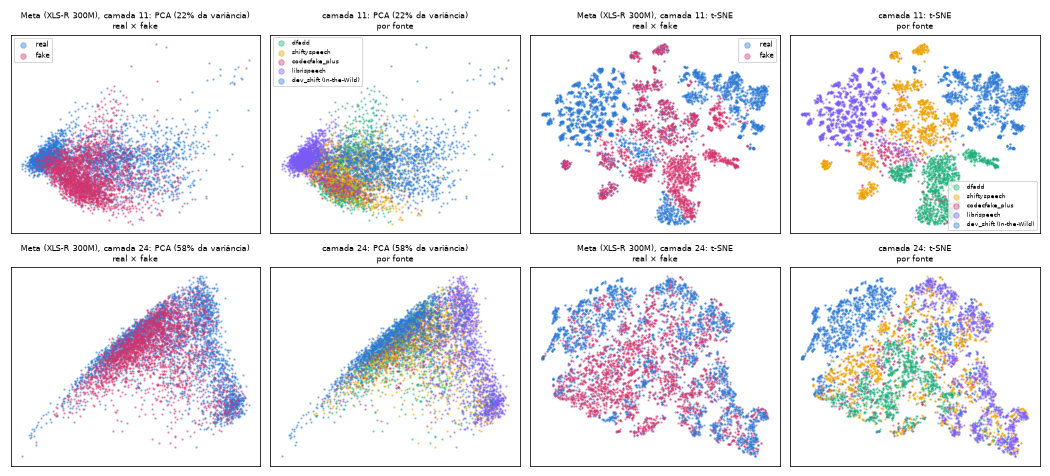

,xlsr
codecfake_plus,352
librispeech,1412
shiftyspeech,1412
dev_shift (In-the-Wild),1412
dfadd,1412


In [4]:
figura(R / f"v6_projecao{SUFIXO}.png")
rel = ler(R / f"v6_relatorio{SUFIXO}.json")
if rel and isinstance(rel.get("projecao"), dict):
    display(pd.DataFrame({m: v["por_fonte"] for m, v in rel["projecao"].items()}))

**Como ler:** se, na cor por fonte, cada fonte forma uma "ilha" e, dentro dela, real e fake se separam, o modelo carrega muita informação de gravação (já visto na v4: a camada 7 reconhece o banco de origem dos reais com acurácia balanceada 0,80) e a cabeça linear consegue separar real × fake dentro de cada ilha. A projeção da CNN da v3 (opcional) **não** foi feita nesta rodada.

## 5. Análise exploratória

### 5.1 Onde ficam as pistas em cada modelo (AUC por camada)
**O que faz:** para cada uma das 25 saídas de cada modelo, uma regressão logística (C escolhido pela pior fonte) e a AUC em cada fonte de decisão. **Por quê:** os dois modelos têm 24 camadas, e a v5 mostrou que as pistas ficam em lugares diferentes (WavLM mais embaixo).

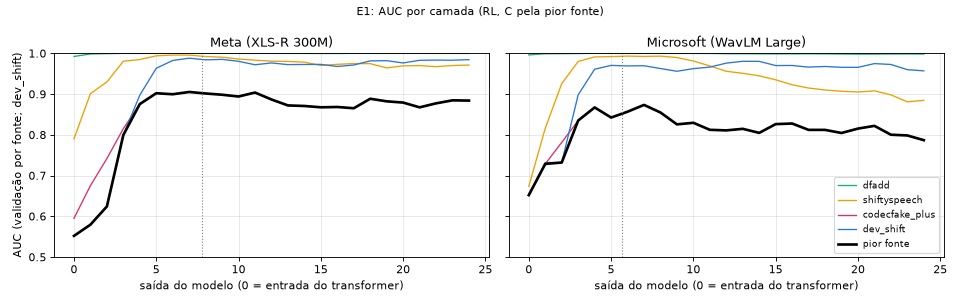

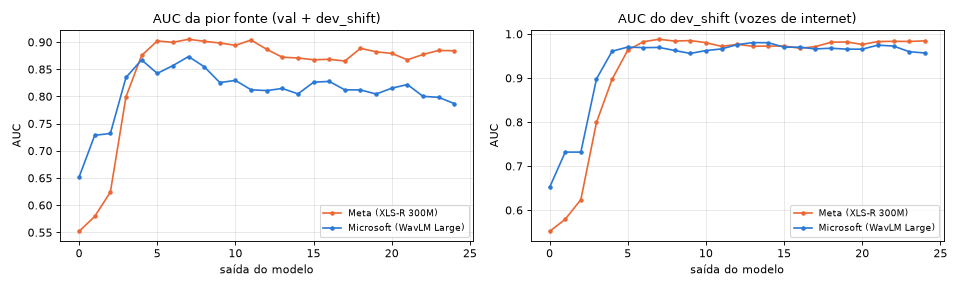

,modelo,camada,C (pior fonte),AUC pior fonte,fonte pior,AUC dfadd,AUC shiftyspeech,AUC codecfake_plus,AUC dev_shift,AUC média (G),"val EER média por fonte (3), regra v4"
0,xlsr,0,0.001,0.5518,dev_shift,0.9923,0.7902,0.5948,0.5518,0.7323,0.2218
1,xlsr,1,1.000,0.5794,dev_shift,0.9984,0.9011,0.6752,0.5794,0.7885,0.1906
2,xlsr,2,1.000,0.6241,dev_shift,0.9992,0.9297,0.7416,0.6241,0.8237,0.1637
3,xlsr,3,0.010,0.7995,dev_shift,0.9999,0.9806,0.8153,0.7995,0.8988,0.1069
4,xlsr,4,1.000,0.8755,codecfake_plus,0.9998,0.9847,0.8755,0.8974,0.9393,0.0872
5,xlsr,5,1.000,0.9020,codecfake_plus,1.0000,0.9939,0.9020,0.9633,0.9648,0.0608
6,xlsr,6,0.100,0.8996,codecfake_plus,1.0000,0.9957,0.8996,0.9825,0.9694,0.0623
7,xlsr,7,0.100,0.9052,codecfake_plus,1.0000,0.9956,0.9052,0.9881,0.9722,0.0599
8,xlsr,8,1.000,0.9014,codecfake_plus,0.9999,0.9922,0.9014,0.9840,0.9694,0.0639
9,xlsr,9,0.100,0.8984,codecfake_plus,0.9999,0.9906,0.8984,0.9852,0.9685,0.0658


In [5]:
figura(R / f"v6_e1_camadas{SUFIXO}.png")
figura(R / f"v6_camadas_meta_microsoft{SUFIXO}.png")
t = tabela(R / f"v6_e1_camadas{SUFIXO}.csv",
           ["modelo", "camada", "C (pior fonte)", "AUC pior fonte", "fonte pior", "AUC dfadd", "AUC shiftyspeech",
            "AUC codecfake_plus", "AUC dev_shift", "AUC média (G)", "val EER média por fonte (3), regra v4"])

In [6]:
if e1:
    rp = e1["reproducao_v4"]
    if rp.get("feita"):
        display(Markdown(f"**Reprodução da v4 (XLS-R):** com o C escolhido pela regra da v4, a maior diferença de EER média "
                         f"por fonte por camada contra `results/v4_camadas.csv` foi de **{rp['dif_max_pontos']} ponto** "
                         f"(camada {rp['camada_dif_max']}; limite 0,5) → **{'passou' if rp['passou'] else 'NÃO passou'}**. "
                         f"A referência v4 (camadas 5, 6, 7; C = 0,1) recalculada difere das notas gravadas na v4 em "
                         f"{e1['v4_ref_dif_max_notas_gravadas']} (logit)."))

**Reprodução da v4 (XLS-R):** com o C escolhido pela regra da v4, a maior diferença de EER média por fonte por camada contra `results/v4_camadas.csv` foi de **0.0 ponto** (camada 24; limite 0,5) → **passou**. A referência v4 (camadas 5, 6, 7; C = 0,1) recalculada difere das notas gravadas na v4 em {'val': 0.0, 'dev_shift': 0.0} (logit).

### 5.2 Os dois modelos erram nos mesmos áudios?
**O que faz:** a correlação das notas (logits) dos dois modelos, por classe, e a tabela 2×2 de acertos (cada modelo no seu limiar A, o ponto de EER da validação). **Por quê:** juntar dois classificadores só ajuda se eles **não** errarem sempre juntos; isso foi medido **antes** de comparar as fusões.

,conjunto,classe,n,Pearson,Spearman
0,validação,real,6004,0.570,0.529
1,validação,fake,13995,0.716,0.674
2,dev_shift,real,8633,0.772,0.724
3,dev_shift,fake,1981,0.608,0.509


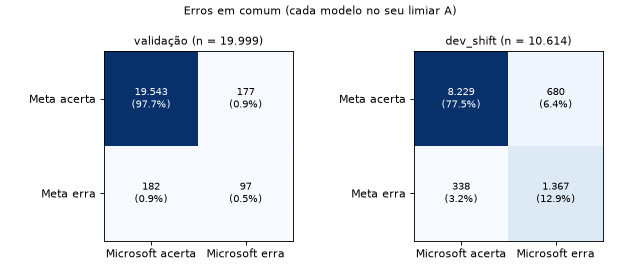

,os dois acertam,só a Meta acerta,só a Microsoft acerta,os dois erram,os dois acertam (%),só a Meta acerta (%),só a Microsoft acerta (%),os dois erram (%),n
validação,19543.0,177.0,182.0,97.0,97.72,0.89,0.91,0.49,19999.0
validação (reais),5871.0,49.0,51.0,33.0,97.78,0.82,0.85,0.55,6004.0
validação (fakes),13672.0,128.0,131.0,64.0,97.69,0.91,0.94,0.46,13995.0
dev_shift,8229.0,680.0,338.0,1367.0,77.53,6.41,3.18,12.88,10614.0
dev_shift (reais),6298.0,678.0,318.0,1339.0,72.95,7.85,3.68,15.51,8633.0
dev_shift (fakes),1931.0,2.0,20.0,28.0,97.48,0.10,1.01,1.41,1981.0


In [7]:
e2 = ler(R / f"v6_e2_resumo{SUFIXO}.json")
if e2:
    display(pd.DataFrame(e2["correlacao"]).round(3))
    figura(R / f"v6_erros_2x2{SUFIXO}.png")
    display(pd.DataFrame({k: v for k, v in e2["erros_2x2"].items() if k != "limiar A (logit)"}).T)
else:
    pendente("o resumo da E2")

## 6. Treinamento: o funil

Nada aqui foi treinado pelo notebook: os scripts treinaram, uma etapa por processo, e gravaram as notas por clipe. Tudo é escolhido na **validação + dev_shift**.

### 6.1 E1 · Meta × Microsoft (melhor cabeça de cada um)
**O que faz:** para cada modelo, a melhor entre as 25 camadas sozinhas, `concat_top3` e `concat_top4` (as 3 ou 4 melhores camadas lado a lado), pela AUC da pior fonte; depois, o bootstrap pareado da diferença. **Regressão logística** (Aula 4): uma camada linear com sigmoide; o C controla a **regularização** L2 (C pequeno = pesos pequenos = menos overfitting).

In [8]:
tabela(R / f"v6_e1_cabecas{SUFIXO}.csv",
       ["modelo", "cabeça", "camadas", "C", "AUC pior fonte", "fonte pior", "AUC média (G)", "acc bal média (G)",
        "EER média (G)", "dev AUC", "val EER média por fonte (3)", "é a melhor do modelo"])
if e1:
    c = e1["bootstrap_wavlm_menos_xlsr"]
    display(Markdown(f"**Bootstrap pareado (Microsoft − Meta), AUC da pior fonte:** {c['dif AUC pior (desafiante - atual)']:+.4f} "
                     f"(IC95 {c['IC95'][0]:+.4f} a {c['IC95'][1]:+.4f}; {c['reamostragens válidas']} reamostragens) → "
                     f"**{'diferença relevante' if c['relevante'] else 'sem diferença relevante a favor da Microsoft'}**."))

,modelo,cabeça,camadas,C,AUC pior fonte,fonte pior,AUC média (G),acc bal média (G),EER média (G),dev AUC,val EER média por fonte (3),é a melhor do modelo
0,xlsr,concat_top3,"[5, 7, 11]",0.1,0.9046,codecfake_plus,0.9701,0.9131,0.0659,0.9798,0.0669,False
1,xlsr,concat_top4,"[5, 7, 8, 11]",1.0,0.9072,codecfake_plus,0.9694,0.9050,0.0639,0.9769,0.0628,True
2,wavlm,concat_top3,"[4, 6, 7]",1.0,0.8906,codecfake_plus,0.9613,0.9038,0.0740,0.9613,0.0707,True
3,wavlm,concat_top4,"[4, 6, 7, 8]",1.0,0.8879,codecfake_plus,0.9607,0.9070,0.0782,0.9624,0.0761,False
4,xlsr,"v4_ref (concat 5,6,7; C=0,1)","[5, 6, 7]",0.1,0.9031,codecfake_plus,0.9708,0.9125,0.0591,0.9833,0.0592,NaN


**Bootstrap pareado (Microsoft − Meta), AUC da pior fonte:** -0.0166 (IC95 -0.0481 a +0.0011; 2000 reamostragens) → **sem diferença relevante a favor da Microsoft**.

### 6.2 E2 · Fusão dos dois modelos
- **(a) média das notas:** cada logit padronizado com a média e o desvio da validação; média simples. Zero parâmetros novos.
- **(c) stacking:** uma regressão logística de **duas entradas** (as duas notas) aprende quanto confiar em cada modelo. Para a nota da validação não ser "dentro da amostra", usa **cross-fitting por fonte**: a nota de cada fonte vem de uma regressão treinada nas outras fontes. ⚠️ Fora da trilha.
- **(b) vetores colados:** os vetores das melhores camadas dos dois modelos lado a lado, cada bloco com o mesmo peso, e uma regressão logística por cima (milhares de pesos).
- **Por que não máximo, votação ou atenção?** Os dois primeiros jogam fora a confiança de cada modelo; o terceiro tem parâmetros demais para a validação que temos.

In [9]:
tabela(R / f"v6_e2_fusao{SUFIXO}.csv", ["sistema", "escolhido", "AUC pior fonte", "fonte pior", "AUC média (G)",
                                        "acc bal média (G)", "dev AUC", "AUC codecfake_plus", "AUC dev_shift"])
if e2:
    display(Markdown("**Pesos do stacking** (entradas padronizadas; modelo 1 = Meta, modelo 2 = Microsoft):"))
    display(pd.DataFrame(e2["stacking_coeficientes"]).round(3))
    display(Markdown(f"**Vencedor da fusão (regra média → stacking → colados): `{e2['vencedor_fusao']}`**"))

,sistema,escolhido,AUC pior fonte,fonte pior,AUC média (G),acc bal média (G),dev AUC,AUC codecfake_plus,AUC dev_shift
0,fusao_colados (C=0.001),False,0.7730,codecfake_plus,0.9289,0.8498,0.9963,0.7730,0.9963
1,fusao_colados (C=0.01),False,0.7927,codecfake_plus,0.9411,0.9026,0.9961,0.7927,0.9961
2,fusao_colados (C=0.1),False,0.8163,codecfake_plus,0.9505,0.9154,0.9953,0.8163,0.9953
3,fusao_colados (C=1),True,0.8744,codecfake_plus,0.9660,0.9246,0.9919,0.8744,0.9919
4,xlsr_melhor,True,0.9072,codecfake_plus,0.9694,0.9050,0.9769,0.9072,0.9769
5,wavlm_melhor,True,0.8906,codecfake_plus,0.9613,0.9038,0.9613,0.8906,0.9613
6,fusao_media,True,0.9051,codecfake_plus,0.9698,0.9138,0.9762,0.9051,0.9762
7,fusao_stacking,True,0.9055,codecfake_plus,0.9700,0.9130,0.9766,0.9055,0.9766
8,fusao_colados,True,0.8744,codecfake_plus,0.9660,0.9246,0.9919,0.8744,0.9919


**Pesos do stacking** (entradas padronizadas; modelo 1 = Meta, modelo 2 = Microsoft):

,dobra (fonte fora),intercepto,peso modelo 1,peso modelo 2
0,codecfake_plus,4.960,5.520,5.008
1,dfadd,3.643,3.815,3.370
2,librispeech,4.230,4.266,3.945
3,shiftyspeech,3.962,4.182,3.580
4,validação inteira (usada no dev_shift e no teste),4.219,4.431,3.979


**Vencedor da fusão (regra média → stacking → colados): `fusao_media`**

### 6.3 E3 · Qual front-end?
**Regra:** só Meta → só Microsoft → fusão; cada opção mais complexa só entra se superar a atual com diferença relevante.

In [10]:
e3 = ler(R / f"v6_e3_frontend{SUFIXO}.json")
if e3:
    display(pd.DataFrame({k: {m: v.get(m) for m in ("AUC pior fonte", "fonte pior", "AUC média (G)", "acc bal média (G)", "dev AUC")}
                          for k, v in e3["metricas"].items()}).T)
    display(Markdown(f"**Vencedor: `{e3['vencedor']}`.** {e3['razao']}"))
else:
    pendente("a decisão da E3")

,AUC pior fonte,fonte pior,AUC média (G),acc bal média (G),dev AUC
xlsr,0.907174,codecfake_plus,0.96935,0.905029,0.976896
wavlm,0.890568,codecfake_plus,0.961255,0.903765,0.961338
fusao_media,0.905099,codecfake_plus,0.969758,0.913831,0.976172


**Vencedor: `xlsr`.** xlsr ficou: wavlm × xlsr: dif -0.0166, IC95 [-0.0481, +0.0011] -> não relevante; fusao_media × xlsr: dif -0.0021, IC95 [-0.0122, +0.0076] -> não relevante

### 6.4 E4 · Três cabeças básicas, uma de cada vez
- **RL básica:** a melhor camada única (pela pior fonte, com C = 1), C = 1. É o "transfer learning puro": modelo congelado + classificador linear.
- **MLP básico** (Aula de redes neurais): a mesma entrada, uma camada escondida de 256 neurônios com ReLU e **dropout** 0,3 (desliga neurônios ao acaso no treino, uma regularização), AdamW, **early stopping** pela validação (para quando a validação para de melhorar: o remédio clássico contra overfitting). ⚠️ Fora da trilha: o AdamW.
- **CNN básica** (Aula de CNN): em vez de olhar uma camada só, olha **as 25 camadas como uma sequência** e passa um filtro de tamanho 3 ao longo delas (o filtro vê três camadas vizinhas de cada vez, como numa imagem ele veria três pixels vizinhos). ⚠️ Fora da trilha: a convolução anda pelas camadas do modelo, não pelo tempo (o tempo já foi resumido em média e desvio). Ela recebe média **e** desvio (2.048 números por camada), a RL e o MLP só a média.
- **Regra:** RL → MLP → CNN; uma rede só toma o lugar se ganhar com diferença relevante **em cada uma das 3 seeds**.

In [11]:
tabela(R / f"v6_e4_cabecas{SUFIXO}.csv", ["sistema", "seed", "parâmetros", "segundos", "melhor época", "AUC pior fonte",
                                          "fonte pior", "AUC média (G)", "acc bal média (G)", "EER média (G)", "dev AUC",
                                          "AUC dfadd", "AUC shiftyspeech", "AUC codecfake_plus", "AUC dev_shift"])
e4 = ler(R / f"v6_e4_resumo{SUFIXO}.json")
if e4:
    for c in e4["comparacoes"]:
        display(Markdown(f"- **{c['desafiante']} × {c['atual']}:** " + "; ".join(
            f"{r['dif AUC pior (desafiante - atual)']:+.4f} (IC95 {r['IC95'][0]:+.4f} a {r['IC95'][1]:+.4f})"
            + (" relevante" if r["relevante"] else "") for r in c["por seed"])
            + f" → {'toma o lugar' if c['relevante em todas as seeds'] else 'não toma o lugar'}"))
    display(Markdown(f"**Cabeça vencedora: {e4['vencedor']}** (camada da RL básica: {e4['camada_basica']})."))

,sistema,seed,parâmetros,segundos,melhor época,AUC pior fonte,fonte pior,AUC média (G),acc bal média (G),EER média (G),dev AUC,AUC dfadd,AUC shiftyspeech,AUC codecfake_plus,AUC dev_shift
0,RL básica,-,1025.0,2.2000,NaN,0.9037,codecfake_plus,0.9647,0.9094,0.0725,0.9719,0.9998,0.9832,0.9037,0.9719
1,MLP básico s42,42,262657.0,2.3000,"{""xlsr"": 4}",0.9116,codecfake_plus,0.9708,0.9222,0.0686,0.9853,1.0000,0.9864,0.9116,0.9853
2,MLP básico s123,123,262657.0,1.5000,"{""xlsr"": 2}",0.9056,codecfake_plus,0.9695,0.9196,0.0702,0.9886,1.0000,0.9839,0.9056,0.9886
3,MLP básico s2026,2026,262657.0,1.7000,"{""xlsr"": 3}",0.9022,codecfake_plus,0.9675,0.9144,0.0705,0.9808,1.0000,0.9868,0.9022,0.9808
4,"MLP básico (média das 3 seeds, só reportado)",média,262657.0,1.8333,NaN,0.9065,NaN,0.9693,0.9188,0.0698,0.9849,1.0000,0.9857,0.9065,0.9849
5,CNN básico s42,42,405825.0,15.9000,"{""xlsr"": 11}",0.9062,codecfake_plus,0.9704,0.9233,0.0595,0.9786,1.0000,0.9967,0.9062,0.9786
6,CNN básico s123,123,405825.0,10.1000,"{""xlsr"": 5}",0.9081,codecfake_plus,0.9719,0.9268,0.0603,0.9828,1.0000,0.9969,0.9081,0.9828
7,CNN básico s2026,2026,405825.0,13.9000,"{""xlsr"": 9}",0.9104,codecfake_plus,0.9718,0.9280,0.0588,0.9792,1.0000,0.9975,0.9104,0.9792
8,"CNN básico (média das 3 seeds, só reportado)",média,405825.0,13.3000,NaN,0.9082,NaN,0.9714,0.9260,0.0595,0.9802,1.0000,0.9970,0.9082,0.9802
9,"v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1)",-,NaN,NaN,NaN,0.9031,codecfake_plus,0.9708,0.9125,0.0591,0.9833,1.0000,0.9969,0.9031,0.9833


- **MLP × RL:** +0.0079 (IC95 -0.0076 a +0.0234); +0.0018 (IC95 -0.0129 a +0.0167); -0.0015 (IC95 -0.0173 a +0.0141) → não toma o lugar

- **CNN × RL:** +0.0025 (IC95 -0.0122 a +0.0181); +0.0043 (IC95 -0.0117 a +0.0209); +0.0066 (IC95 -0.0093 a +0.0239) → não toma o lugar

**Cabeça vencedora: RL** (camada da RL básica: {'xlsr': [11]}).

### 6.5 E5 · Apertar a cabeça vencedora (uma modificação de cada vez)
Cada passo **só fica** se a AUC da pior fonte subir pelo menos 0,003 e a AUC do dev_shift não cair mais que 0,01. Atenção: esta régua não usa bootstrap; passos pequenos podem ser ruído da validação. Na RL: (1) zona de camadas (uma ou três vizinhas), (2) grade ampla de C (a força da regularização), (3) peso igual por fonte de treino, (4) regra do limiar (A = EER global da validação; C = mediana dos limiares de EER por fonte; D = 5% de falso alarme por fonte), escolhida deixando uma fonte de fora de cada vez.

In [12]:
tabela(R / f"v6_e5_passos{SUFIXO}.csv", ["passo", "modificação", "AUC pior antes", "AUC pior depois", "ganho",
                                         "fonte pior depois", "dev AUC antes", "dev AUC depois", "mantida",
                                         "acc bal LOSO A", "acc bal LOSO C", "acc bal LOSO D",
                                         "dev acc bal A", "dev acc bal C", "dev acc bal D"])
e5 = ler(R / f"v6_e5_resumo{SUFIXO}.json")
if e5:
    tabela(R / f"v6_e5_limiar_loso{SUFIXO}.csv")
    c = e5["final_menos_base_bootstrap"]
    display(Markdown(f"**Sistema final:** `{json.dumps(e5['spec_final'], ensure_ascii=False)}`; limiar **{e5['regra_limiar']}** "
                     f"(logits: {json.dumps({k: round(v, 3) for k, v in e5['limiares'].items()})}). "
                     f"Final − básica (bootstrap, só para informar): {c['dif AUC pior (desafiante - atual)']:+.4f} "
                     f"(IC95 {c['IC95'][0]:+.4f} a {c['IC95'][1]:+.4f})."))

,passo,modificação,AUC pior antes,AUC pior depois,ganho,fonte pior depois,dev AUC antes,dev AUC depois,mantida,acc bal LOSO A,acc bal LOSO C,acc bal LOSO D,dev acc bal A,dev acc bal C,dev acc bal D
0,1,zona de camadas: {'xlsr': [11]},0.9037,0.9037,0.0000,codecfake_plus,0.9719,0.9719,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2,grade ampla de C: {'xlsr': 10.0},0.9037,0.9047,0.0009,codecfake_plus,0.9719,0.9708,False,NaN,NaN,NaN,NaN,NaN,NaN
2,3,pesos iguais por fonte (sample_weight),0.9037,0.9100,0.0062,codecfake_plus,0.9719,0.9719,True,NaN,NaN,NaN,NaN,NaN,NaN
3,4,regra de limiar: A,0.9100,0.9100,0.0000,NaN,NaN,NaN,False,0.9156,0.9155,0.9171,0.8875,0.8877,0.869


,regra,fonte deixada de fora,limiar (logit),acurácia balanceada
0,A,dfadd,-1.7946,0.9913
1,C,dfadd,-1.7677,0.9916
2,D,dfadd,0.9539,0.9933
3,A,shiftyspeech,-0.2703,0.9319
4,C,shiftyspeech,-1.9412,0.9283
5,D,shiftyspeech,-6.0623,0.8838
6,A,codecfake_plus,-0.5467,0.8235
7,C,codecfake_plus,-0.3231,0.8265
8,D,codecfake_plus,-6.0623,0.8744


**Sistema final:** `{"tipo": "rl", "frontend": "xlsr", "camadas": {"xlsr": [11]}, "pesos": "fonte", "C": {"xlsr": 1.0}}`; limiar **A** (logits: {"A": -0.536, "C": -0.497, "D": -2.554}). Final − básica (bootstrap, só para informar): +0.0062 (IC95 +0.0014 a +0.0111).

### 6.6 A tabela do funil
Uma linha por etapa: candidatos, métrica, vencedor, por quê, a alternativa descartada e os números de cada candidato.

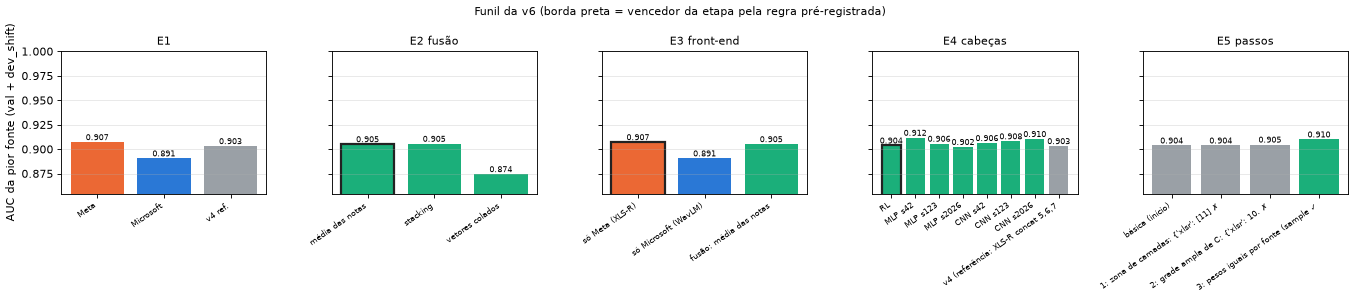

| etapa                         | candidatos                                                                                                                                                                                                                                                            | métrica                                                                                                          | vencedor                                  | por quê                                                                                                                                                                                  | alternativa descartada                                                                | AUC pior fonte (cada candidato)                                                                                                                                                                                                                                                                                                              | acc. balanceada média (cada candidato)                                                                                                                                                                                                                                                                                             |
|:------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------|:------------------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| E1 Meta × Microsoft           | Meta (concat_top4) | Microsoft (concat_top3) | v4 (referência)                                                                                                                                                                                                        | AUC da pior fonte (bootstrap pareado por locutor)                                                                | empate (a E3 decide: fica o mais simples) | Microsoft − Meta = -0.0166 (IC95 -0.0481 a +0.0011)                                                                                                                                      | —                                                                                     | Meta (concat_top4): 0.9072; Microsoft (concat_top3): 0.8906; v4 (referência): 0.9031                                                                                                                                                                                                                                                         | Meta (concat_top4): 0.905; Microsoft (concat_top3): 0.904; v4 (referência): 0.913                                                                                                                                                                                                                                                  |
| E2 fusão                      | fusão: média das notas | fusão: stacking | fusão: vetores colados                                                                                                                                                                                                     | AUC da pior fonte; regra média → stacking → colados                                                              | fusão: média das notas                    | fica fusao_media: fusao_stacking − fusao_media: +0.0004 (IC95 -0.0005 a +0.0013) → não relevante; fusao_colados − fusao_media: -0.0306 (IC95 -0.0461 a -0.0170) → não relevante          | fusão: stacking, fusão: vetores colados                                               | fusão: média das notas: 0.9051; fusão: stacking: 0.9055; fusão: vetores colados: 0.8744                                                                                                                                                                                                                                                      | fusão: média das notas: 0.914; fusão: stacking: 0.913; fusão: vetores colados: 0.925                                                                                                                                                                                                                                               |
| E3 front-end                  | só Meta (XLS-R) | só Microsoft (WavLM) | fusão: média das notas                                                                                                                                                                                                       | AUC da pior fonte; regra Meta → Microsoft → fusão                                                                | só Meta (XLS-R)                           | fica xlsr: wavlm − xlsr: -0.0166 (IC95 -0.0481 a +0.0011) → não relevante; fusao_media − xlsr: -0.0021 (IC95 -0.0122 a +0.0076) → não relevante                                          | só Microsoft (WavLM), fusão: média das notas                                          | só Meta (XLS-R): 0.9072; só Microsoft (WavLM): 0.8906; fusão: média das notas: 0.9051                                                                                                                                                                                                                                                        | só Meta (XLS-R): 0.905; só Microsoft (WavLM): 0.904; fusão: média das notas: 0.914                                                                                                                                                                                                                                                 |
| E4 cabeças básicas            | RL básica | MLP básico s42 | MLP básico s123 | MLP básico s2026 | MLP básico (média das 3 seeds, só reportado) | CNN básico s42 | CNN básico s123 | CNN básico s2026 | CNN básico (média das 3 seeds, só reportado) | v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1) | AUC da pior fonte; regra RL → MLP → CNN (MLP/CNN precisam ganhar nas 3 seeds)                                    | RL                                        | fica RL: MLP − RL por seed: +0.0079, +0.0018, -0.0015 → não relevante nas 3; CNN − RL por seed: +0.0025, +0.0043, +0.0066 → não relevante nas 3                                          | MLP, CNN                                                                              | RL básica: 0.9037; MLP básico s42: 0.9116; MLP básico s123: 0.9056; MLP básico s2026: 0.9022; MLP básico (média das 3 seeds, só reportado): 0.9065; CNN básico s42: 0.9062; CNN básico s123: 0.9081; CNN básico s2026: 0.9104; CNN básico (média das 3 seeds, só reportado): 0.9082; v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1): 0.9031 | RL básica: 0.909; MLP básico s42: 0.922; MLP básico s123: 0.920; MLP básico s2026: 0.914; MLP básico (média das 3 seeds, só reportado): 0.919; CNN básico s42: 0.923; CNN básico s123: 0.927; CNN básico s2026: 0.928; CNN básico (média das 3 seeds, só reportado): 0.926; v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1): 0.913 |
| E5 maximização                | passo 1: zona de camadas: {'xlsr': [11]} | passo 2: grade ampla de C: {'xlsr': 10.0} | passo 3: pesos iguais por fonte (sample_weight) | passo 4: regra de limiar: A                                                                                                  | manter se pior fonte +0,003 e dev_shift sem cair > 0,01; limiar por validação cruzada deixando uma fonte de fora | pesos iguais por fonte (sample_weight)    | pior fonte final 0.9100; regra de limiar A                                                                                                                                               | zona de camadas: {'xlsr': [11]}; grade ampla de C: {'xlsr': 10.0}; regra de limiar: A | passo 1: zona de camadas: {'xlsr': [11]}: 0.9037; passo 2: grade ampla de C: {'xlsr': 10.0}: 0.9047; passo 3: pesos iguais por fonte (sample_weight): 0.9100; passo 4: regra de limiar: A: 0.9100                                                                                                                                            | passo 1: zona de camadas: {'xlsr': [11]}: 0.909; passo 2: grade ampla de C: {'xlsr': 10.0}: 0.912; passo 3: pesos iguais por fonte (sample_weight): 0.909; passo 4: regra de limiar: A: —                                                                                                                                          |
| E6 teste (uma vez, só mostra) | F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1 | F1: front-end vencedor (xlsr) + RL básica (camada {'xlsr': [11]}, C = 1) | F2: sistema final da E5 (RL, xlsr), limiar A                                                                            | acurácia e acurácia balanceada por banco (nada é escolhido aqui)                                                 | — (o teste não escolhe)                   | F0: média da acurácia nos 3 principais 0.851 (trivial 0.597); F1: média da acurácia nos 3 principais 0.828 (trivial 0.597); F2: média da acurácia nos 3 principais 0.829 (trivial 0.597) | —                                                                                     | F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1: 0.9031; F1: front-end vencedor (xlsr) + RL básica (camada {'xlsr': [11]}, C = 1): 0.9037; F2: sistema final da E5 (RL, xlsr), limiar A: 0.9100 (val + dev_shift)                                                                                                           | F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1: 0.790; F1: front-end vencedor (xlsr) + RL básica (camada {'xlsr': [11]}, C = 1): 0.749; F2: sistema final da E5 (RL, xlsr), limiar A: 0.749 (média dos 3 bancos principais, limiar principal)                                                                    |

In [13]:
figura(R / f"v6_funil{SUFIXO}.png")
if existe(R / f"v6_funil{SUFIXO}.csv"):
    f = pd.read_csv(R / f"v6_funil{SUFIXO}.csv")
    display(Markdown(f.to_markdown(index=False) if hasattr(f, "to_markdown") else f.to_string()))
else:
    pendente("a tabela do funil")

## 7. Avaliação

### 7.1 Finalistas e limiares (gravados antes da E6)
Os três finalistas e os seus limiares foram gravados em `results/v6_finalistas.json` **antes** de qualquer nota de teste. **Limiares:** A = ponto de EER da validação; B = ponto de EER do dev_shift; E5 = o escolhido na E5. Nenhum é ajustado no teste.

Gravado em **2026-11-10T23:23:25**.

,descrição,limiar principal,limiar A (logit),limiar B (logit),limiar E5 (A) (logit),AUC pior fonte (val+dev),dev AUC
F0,"v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7)...",A,-0.04,8.218,-0.04,0.9031,0.9833
F1,front-end vencedor (xlsr) + RL básica (camada ...,A,-0.395,9.199,-0.395,0.9037,0.9719
F2,"sistema final da E5 (RL, xlsr), limiar A",A,-0.536,9.326,-0.536,0.91,0.9719


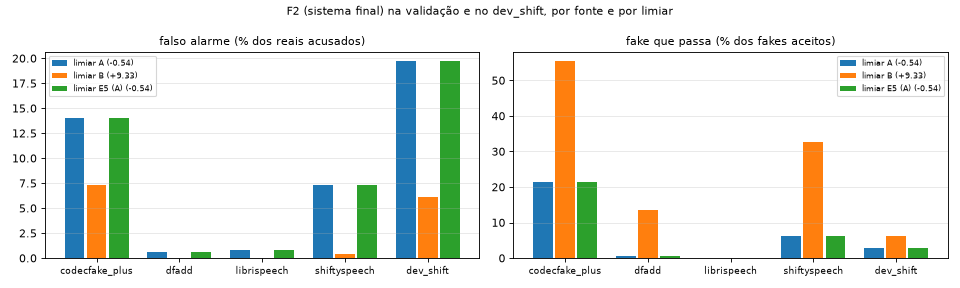

In [14]:
fi = ler(R / f"v6_finalistas{SUFIXO}.json")
if fi:
    display(Markdown(f"Gravado em **{fi['gravado_em']}**."))
    display(pd.DataFrame({k: {"descrição": v["descrição"], "limiar principal": v["limiar_principal"],
                              **{f"limiar {L} (logit)": round(t, 3) for L, t in v["limiares_logit"].items()},
                              "AUC pior fonte (val+dev)": round(v["metricas_val_dev"]["AUC pior fonte"], 4),
                              "dev AUC": round(v["metricas_val_dev"].get("dev AUC", float("nan")), 4)}
                          for k, v in fi["finalistas"].items()}).T)
    figura(R / f"v6_limiares_por_fonte_val{SUFIXO}.png")
else:
    pendente("os finalistas")

### 7.2 Teste (E6, avaliado uma vez)
**Atenção:** os seis bancos de teste já tinham sido consultados na v4 e na v5; este é o terceiro olhar e só serve para **mostrar** os finalistas. **Acurácia sozinha engana** em banco desbalanceado (no BRSpeech-DF, 79% é fake: chutar "fake" sempre já acerta 79%), por isso ela vem ao lado da **acurácia trivial** e da **acurácia balanceada** (média do acerto em reais e em fakes; 0,5 = chute). Os intervalos (bootstrap dentro de cada classe) medem só a amostra de teste, não a variação do treino.

**Cada finalista no seu limiar principal** ({'F0': 'A', 'F1': 'A', 'F2': 'A'}):

sistema                            F0                                                                                        F1                                                                 \
métrica                      acurácia acurácia trivial acurácia balanceada    AUC    EER recall fake falso alarme real acurácia acurácia trivial acurácia balanceada    AUC    EER recall fake   
banco             tipo                                                                                                                                                                           
in_the_wild       principal     0.836            0.500               0.835  0.979  0.068       0.989             0.318    0.807            0.500               0.807  0.972  0.082       0.991   
llamapartialspoof principal     0.855            0.500               0.855  0.925  0.147       0.750             0.040    0.863            0.500               0.863  0.940  0.132       0.766   
brspeech_df       principal     0.863            0.791               0.679  0.842  0.249       0.995             0.636    0.814            0.791               0.576  0.741  0.333       0.985   
coraa             só real       0.833            1.000                 NaN    NaN    NaN         NaN             0.167    0.588            1.000                 NaN    NaN    NaN         NaN   
asvspoof2019_la   secundário    0.981            0.500               0.981  0.999  0.014       0.964             0.001    0.975            0.500               0.975  0.997  0.022       0.956   
asvspoof2021_df   secundário    0.942            0.500               0.942  0.997  0.026       0.993             0.108    0.954            0.500               0.954  0.996  0.026       0.986   

sistema                                              F2                                                                                   
métrica                      falso alarme real acurácia acurácia trivial acurácia balanceada    AUC    EER recall fake falso alarme real  
banco             tipo                                                                                                                    
in_the_wild       principal              0.377    0.812            0.500               0.812  0.972  0.083       0.990             0.366  
llamapartialspoof principal              0.040    0.863            0.500               0.863  0.937  0.136       0.768             0.043  
brspeech_df       principal              0.833    0.813            0.791               0.571  0.744  0.327       0.987             0.845  
coraa             só real                0.412    0.596            1.000                 NaN    NaN    NaN         NaN             0.404  
asvspoof2019_la   secundário             0.006    0.975            0.500               0.975  0.997  0.023       0.957             0.007  
asvspoof2021_df   secundário             0.078    0.950            0.500               0.950  0.996  0.025       0.987             0.088

**Média dos três bancos principais com duas classes** (In-the-Wild, LlamaPartialSpoof, BRSpeech-DF) e falso alarme do CORAA:

,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme,limiar
F0,0.851158,0.789999,0.597046,0.91507,0.1672,A
F1,0.827927,0.748511,0.597046,0.884324,0.4118,A
F2,0.829464,0.748751,0.597046,0.884494,0.4036,A


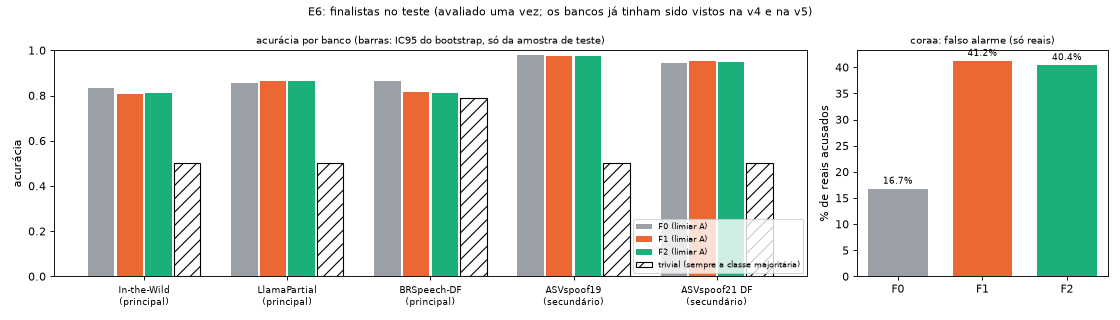

In [15]:
te = ler(R / f"v6_teste_resumo{SUFIXO}.json")
if te:
    t = pd.read_csv(R / f"v6_teste_final{SUFIXO}.csv")
    t = t[(t.conjunto == "teste") & t["limiar principal"]]
    pv = t.pivot_table(index=["banco", "tipo"], columns=["sistema", "métrica"], values="valor", sort=False)
    met = ["acurácia", "acurácia trivial", "acurácia balanceada", "AUC", "EER", "recall fake", "falso alarme real"]
    display(Markdown(f"**Cada finalista no seu limiar principal** ({te['limiar_principal']}):"))
    display(pv.reindex(columns=[(s, m) for s in sorted(te["finalistas"]) for m in met]).round(3))
    display(Markdown("**Média dos três bancos principais com duas classes** (In-the-Wild, LlamaPartialSpoof, BRSpeech-DF) e falso alarme do CORAA:"))
    display(pd.DataFrame(te["resumo_finalistas"]).T.round(4))
    figura(R / f"v6_teste_acuracia{SUFIXO}.png")
else:
    pendente("o resultado da E6")

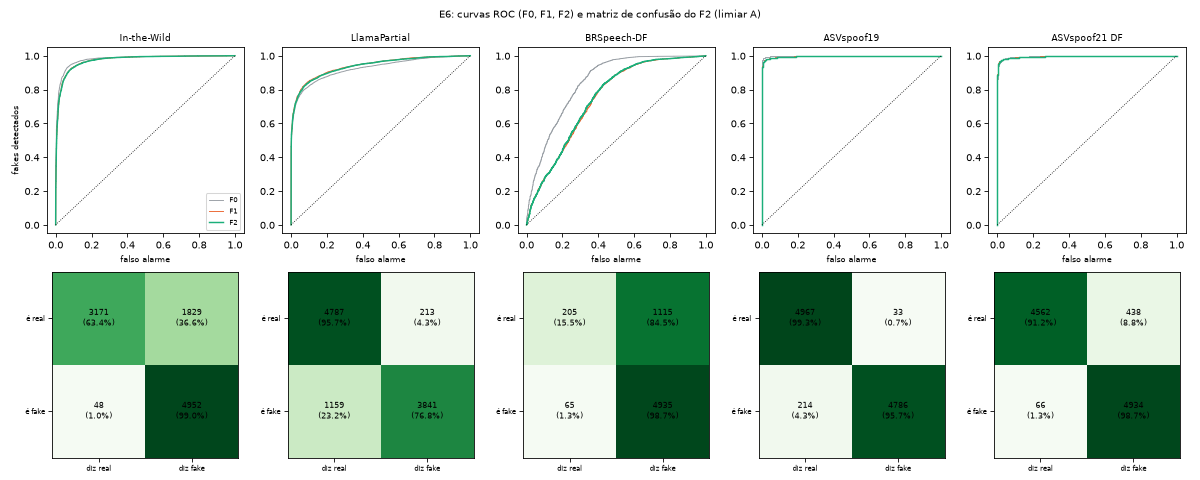

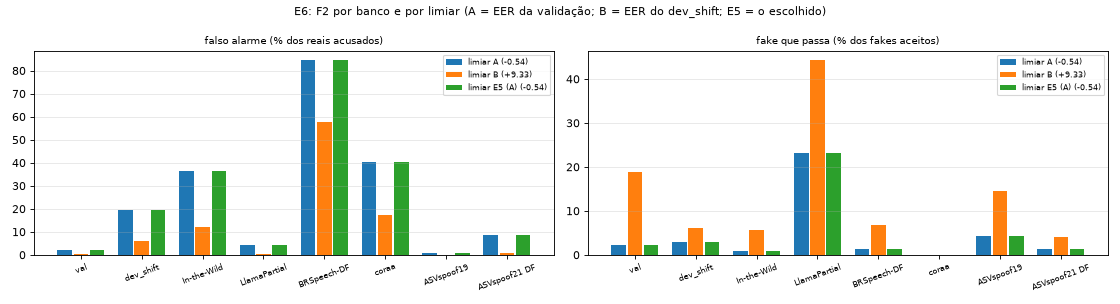

**Todos os limiares** (A, B e E5), média dos três principais:

,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme
F0 | limiar A,0.8512,0.7900,0.597,0.9151,0.1672
F0 | limiar B,0.8361,0.8135,0.597,0.9151,0.0250
F0 | limiar E5 (A),0.8512,0.7900,0.597,0.9151,0.1672
F1 | limiar A,0.8279,0.7485,0.597,0.8843,0.4118
F1 | limiar B,0.8337,0.7887,0.597,0.8843,0.1744
F1 | limiar E5 (A),0.8279,0.7485,0.597,0.8843,0.4118
F2 | limiar A,0.8295,0.7488,0.597,0.8845,0.4036
F2 | limiar B,0.8383,0.7889,0.597,0.8845,0.1728
F2 | limiar E5 (A),0.8295,0.7488,0.597,0.8845,0.4036


**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e o IC95 sem o zero em cada um):

,resultado
F1 − F0 | AUC,não demonstrada
F1 − F0 | acurácia balanceada,não demonstrada
F2 − F0 | AUC,não demonstrada
F2 − F0 | acurácia balanceada,não demonstrada


,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,F1 − F0,AUC,in_the_wild,principal,-0.0066,-0.0091,-0.0036,True
1,F1 − F0,AUC,llamapartialspoof,principal,0.0146,0.0111,0.0182,True
2,F1 − F0,AUC,brspeech_df,principal,-0.1002,-0.1088,-0.0919,True
3,F1 − F0,AUC,asvspoof2019_la,secundário,-0.0021,-0.0028,-0.0014,True
4,F1 − F0,AUC,asvspoof2021_df,secundário,-0.0006,-0.0013,0.0002,False
5,F1 − F0,acurácia balanceada,in_the_wild,principal,-0.0289,-0.0363,-0.0217,True
6,F1 − F0,acurácia balanceada,llamapartialspoof,principal,0.0081,0.0023,0.0139,True
7,F1 − F0,acurácia balanceada,brspeech_df,principal,-0.1037,-0.1167,-0.0928,True
8,F1 − F0,acurácia balanceada,asvspoof2019_la,secundário,-0.0061,-0.0092,-0.0030,True
9,F1 − F0,acurácia balanceada,asvspoof2021_df,secundário,0.0120,0.0071,0.0167,True


**WavLM no teste:** não extraído (nenhum finalista usa); números do colega.

Números do teste da v5 (**do colega, sem notas por clipe**; limiar A):

sistema                 X2                                                    W1                                                    W2                                             
métrica           acurácia acurácia balanceada    AUC falso alarme real acurácia acurácia balanceada    AUC falso alarme real acurácia acurácia balanceada    AUC falso alarme real
banco                                                                                                                                                                              
in_the_wild          0.834               0.834  0.978             0.321    0.826               0.826  0.946             0.336    0.839               0.839  0.950             0.296
llamapartialspoof    0.854               0.854  0.924             0.040    0.830               0.830  0.899             0.112    0.856               0.856  0.914             0.032
brspeech_df          0.863               0.680  0.842             0.634    0.782               0.524  0.557             0.919    0.845               0.643  0.768             0.703
coraa                0.831                 NaN    NaN             0.169    0.127                 NaN    NaN             0.873    0.655                 NaN    NaN             0.345
asvspoof2019_la      0.981               0.981  0.999             0.001    0.944               0.944  0.986             0.055    0.970               0.970  0.996             0.004
asvspoof2021_df      0.942               0.942  0.997             0.109    0.895               0.895  0.986             0.194    0.904               0.904  0.990             0.178

In [16]:
if te:
    figura(R / f"v6_teste_roc_confusao{SUFIXO}.png")
    figura(R / f"v6_teste_limiares{SUFIXO}.png")
    display(Markdown("**Todos os limiares** (A, B e E5), média dos três principais:"))
    display(pd.DataFrame(te["resumo_todos_limiares"]).T.round(4))
    display(Markdown("**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e o IC95 sem o zero em cada um):"))
    display(pd.DataFrame(te["regra_leitura"], index=["resultado"]).T)
    tabela(R / f"v6_teste_diferencas{SUFIXO}.csv")
    display(Markdown(f"**WavLM no teste:** {te['wavlm_no_teste']}."))
    if te.get("colega_v5_teste"):
        c = pd.DataFrame(te["colega_v5_teste"])
        c = c[c.limiar == "A"].pivot_table(index="banco", columns=["sistema", "métrica"], values="valor", sort=False)
        display(Markdown("Números do teste da v5 (**do colega, sem notas por clipe**; limiar A):"))
        display(c.round(3))

## 8. Conclusões

In [17]:
fun = R / f"v6_funil{SUFIXO}.csv"
if existe(fun):
    f = pd.read_csv(fun)
    display(Markdown("**Vencedor de cada etapa (gerado dos arquivos):**\n\n" + "\n".join(
        f"- **{r.etapa}:** {r.vencedor}. {r['por quê']}" for _, r in f.iterrows())))
concl = R / f"v6_conclusao{SUFIXO}.md"
if existe(concl):
    display(Markdown(concl.read_text(encoding="utf-8")))
else:
    display(Markdown("### Conclusão: pendente\n\nO texto da conclusão (o que funcionou, o que não funcionou e por quê) "
                     "é escrito depois de ver os números, em `results/v6_conclusao.md`. As tabelas e os gráficos acima "
                     "já estão completos."))

**Vencedor de cada etapa (gerado dos arquivos):**

- **E1 Meta × Microsoft:** empate (a E3 decide: fica o mais simples). Microsoft − Meta = -0.0166 (IC95 -0.0481 a +0.0011)
- **E2 fusão:** fusão: média das notas. fica fusao_media: fusao_stacking − fusao_media: +0.0004 (IC95 -0.0005 a +0.0013) → não relevante; fusao_colados − fusao_media: -0.0306 (IC95 -0.0461 a -0.0170) → não relevante
- **E3 front-end:** só Meta (XLS-R). fica xlsr: wavlm − xlsr: -0.0166 (IC95 -0.0481 a +0.0011) → não relevante; fusao_media − xlsr: -0.0021 (IC95 -0.0122 a +0.0076) → não relevante
- **E4 cabeças básicas:** RL. fica RL: MLP − RL por seed: +0.0079, +0.0018, -0.0015 → não relevante nas 3; CNN − RL por seed: +0.0025, +0.0043, +0.0066 → não relevante nas 3
- **E5 maximização:** pesos iguais por fonte (sample_weight). pior fonte final 0.9100; regra de limiar A
- **E6 teste (uma vez, só mostra):** — (o teste não escolhe). F0: média da acurácia nos 3 principais 0.851 (trivial 0.597); F1: média da acurácia nos 3 principais 0.828 (trivial 0.597); F2: média da acurácia nos 3 principais 0.829 (trivial 0.597)

### Conclusão (escrita em 2026-11-10, depois de ver os números)

**Em uma frase:** pelas regras pré-registradas, nada superou o XLS-R da Meta com uma regressão logística (nem o WavLM, nem a fusão, nem MLP, nem CNN), e o "sistema final" da v6, escolhido pela AUC da pior fonte, ficou **pior que a v4 no teste**, principalmente em português; a v4 (`concat_top3`, camadas 5, 6, 7) continua sendo o melhor modelo do projeto.

**O que funcionou**
- **O pipeline é reproduzível:** o XLS-R recalculado deu exatamente os números da v4 (diferença 0,0 ponto de EER em todas as 25 camadas; notas da cabeça da v4 idênticas às gravadas), e o F0 reproduziu o teste da v4 (In-the-Wild AUC 0,979; CORAA 16,7% de falso alarme).
- **Os dois modelos nos mesmos clipes:** o WavLM foi extraído em 23 min nos 70.613 clipes do plano da v4, sem nenhum erro de leitura; a comparação é pareada clipe a clipe.
- **A execução sozinha:** vigia, retomada e marcadores funcionaram (a noite oficial terminou numa tentativa, em 0,3 h).

**O que não funcionou (e por quê, até onde dá para saber)**
1. **WavLM (E1):** pior que o XLS-R na AUC da pior fonte (0,891 × 0,907; diferença −0,017, IC95 −0,048 a +0,001): empate pela regra, fica o mais simples. O mesmo resultado da v5.
2. **Fusão (E2/E3):** os dois modelos acertam juntos 97,7% da validação e erram juntos 0,5%; no dev_shift, só a Meta acerta 6,4% e só a Microsoft 3,2%. Os erros não são independentes o bastante (correlação dos logits de 0,51 a 0,77 por classe), e a melhor fusão (média das notas, 0,905) não passou do XLS-R sozinho (0,907). Os vetores colados ficaram ótimos no dev_shift (AUC 0,996), mas piores no CodecFake+ (0,874): mais pesos, mais ajuste ao estúdio.
3. **MLP e CNN (E4):** um pouco acima da RL no ponto (pior fonte 0,902 a 0,912 contra 0,904), mas nenhuma seed com diferença relevante (todos os IC95 incluem o zero). Com o modelo congelado fazendo o trabalho pesado, uma cabeça não linear não acrescenta nada demonstrável (de novo, como as somas ponderadas da v4).
4. **Ajuste fino (E5):** a zona de camadas e a grade ampla de C não mudaram nada (+0,000 e +0,001); só os pesos iguais por fonte passaram a régua (+0,006 na pior fonte, sem bootstrap). A regra de limiar ficou a A (C e D não ganharam 0,005 na validação cruzada).
5. **O teste mostrou o limite da métrica nova:** F1 e F2 (XLS-R, **camada 11 sozinha**, C = 1) ficaram piores que a v4 no In-the-Wild (AUC 0,972 × 0,979), muito piores no BRSpeech-DF (0,74 × 0,84) e acusaram 40% a 41% dos reais do CORAA (v4: 17%); só no LlamaPartialSpoof foram melhores (0,94 × 0,925). Média da acurácia nos três principais: F0 0,851, F1 0,828, F2 0,829 (trivial 0,597).

**A lição principal:** a "AUC da pior fonte" virou, na prática, **a AUC do CodecFake+**: ele foi a pior fonte em todas as cabeças comparadas nas etapas (e em todas as camadas a partir da 4; só em algumas das camadas 0 a 3 a pior era o dev_shift), tem só 352 clipes (de 17 páginas de demonstração, sem locutor) e as diferenças entre candidatos ficaram em milésimos. Escolher pela pior fonte trocou as camadas do meio (5 a 7, mais regularizadas, melhores no dev_shift) pela camada 11 com C = 1, e essa troca piorou exatamente o que a validação não mede: **português**. Uma métrica pensada para não esconder a fonte ruim acabou dependendo de uma fonte pequena e pouco representativa. A régua da E5 (+0,003 sem bootstrap) também é fina demais para essa fonte.

**Ressalvas:** os bancos de teste já tinham sido vistos na v4 e na v5 (o teste aqui só mostra); o bootstrap do teste mede só a amostra de teste; o dev_shift tem 16 locutores; uma única amostra de treino.

**O que fica para o grupo decidir:** seguir com a v4 (F0) como modelo do projeto; e, para escolher melhor no futuro, ter um conjunto de decisão em **português** e uma fonte de codec maior (ideias na seção f do histórico).
